# RoadScan: finish evaluation from saved checkpoints

The four detector trials and reference training completed in notebook 04, version 358996529. The run failed during image-level prediction with CUDA out of memory because the list source was too large. This notebook does **not retrain**. It reuses all frozen split manifests, checkpoint selection and the original development confidence. Test results had not been computed before the failure.

Local Saudi testing is still pending. No claim of worldwide performance or absence of overfitting is justified.

## 1. Restore and verify completed work

Why: preserve the three hours of completed training. Load saved models, configurations and exact data splits. Verify all four checkpoint files. Pin the same Ultralytics release. Rebase data paths only when Kaggle mount names differ; do not change split membership or labels.

In [1]:
from pathlib import Path
import subprocess,sys,json,random,platform,time,shutil,hashlib,re,gc
subprocess.check_call([sys.executable,'-m','pip','install','-q','ultralytics==8.4.177'])
import numpy as np,pandas as pd,torch,torchvision,ultralytics,yaml
from PIL import Image,ImageDraw
from ultralytics import YOLO
from IPython.display import display,Markdown
from torch import nn
from torch.utils.data import Dataset,DataLoader
from torchvision import models,transforms
from sklearn.metrics import f1_score,precision_recall_fscore_support
import matplotlib.pyplot as plt
SEED=42
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
assert torch.cuda.is_available(),'GPU required for evaluation'
DEVICE='cuda:0';torch.set_num_threads(2)
BASE=Path('/kaggle/working/roadscan_experiments')
origins=list(Path('/kaggle/input').rglob('selection.json'))
assert len(origins)==1,f'Attach version 2 output exactly once: {origins}'
ORIGIN=origins[0].parent
shutil.copytree(ORIGIN,BASE,dirs_exist_ok=True)
roots=[p.parent.parent for p in Path('/kaggle/input').rglob('train/images') if (p.parent.parent/'train/labels').is_dir()]
assert len(roots)==1,f'Attach original roadscan-yolo dataset: {roots}'
SRC=roots[0]
CLASSES=['D00','D10','D20','D40']
splits={name:pd.read_csv(BASE/(name+'_manifest.csv')) for name in ['train','in_domain_dev','china_dev','in_domain_test','us_external','development']}
# Rebase immutable source image/label paths if Kaggle mounting names changed.
for name,data in splits.items():
 for col in ['path','label']:
  data[col]=[str(SRC/str(p).split('/RoadScan_yolo/',1)[1]) for p in data[col]]
 data.to_csv(BASE/(name+'_manifest.csv'),index=False)
 (BASE/(name+'.txt')).write_text(chr(10).join(data.path))
 assert all(Path(p).is_file() for p in data.path),name+' images missing'
train=splits['train'];dev=splits['development']
def write_yaml(name):
 p=BASE/('eval_'+name+'.yaml')
 p.write_text(yaml.safe_dump(dict(path=str(SRC),train=str(BASE/'train.txt'),val=str(BASE/(name+'.txt')),names=dict(enumerate(CLASSES)))))
 return str(p)
DATA=write_yaml('development')
YAMLS={name:write_yaml(name) for name in ['in_domain_dev','china_dev','in_domain_test','us_external']}
records=pd.read_csv(BASE/'experiments.csv').to_dict('records')
experiments=pd.DataFrame(records).sort_values('map50_95',ascending=False)
WINNER=json.loads((BASE/'selection.json').read_text())['checkpoint']
assert Path(WINNER).is_file(),'Original selected checkpoint not found'
for r in records:assert Path(r['checkpoint']).is_file(),r['checkpoint']
CONF=json.loads((BASE/'operating_point.json').read_text())['confidence']
config=json.loads((BASE/'baseline_config.json').read_text());baseline_th=config['thresholds']
y_dev=dev[CLASSES].to_numpy(dtype=int)
TF=transforms.Compose([transforms.Resize((384,384)),transforms.ToTensor(),transforms.Normalize(config['mean'],config['std'])])
class RoadImages(Dataset):
    def __init__(self,records): self.records=records.reset_index(drop=True)
    def __len__(self): return len(self.records)
    def __getitem__(self,i):
        r=self.records.iloc[i]
        with Image.open(r.path) as im: x=TF(im.convert('RGB'))
        return x,torch.tensor(r[CLASSES].to_numpy(dtype=np.float32))

def loader(data,shuffle=False): return DataLoader(RoadImages(data),batch_size=32,shuffle=shuffle,num_workers=2,pin_memory=True)

@torch.inference_mode()
def resnet_probs(data):
    resnet.eval();out=[]
    for x,_ in loader(data):out.append(torch.sigmoid(resnet(x.to(DEVICE))).cpu().numpy())
    return np.concatenate(out)

def tune_thresholds(y,p):
    grid=np.arange(.05,.96,.05)
    return [float(max(grid,key=lambda t:f1_score(y[:,i],p[:,i]>=t,zero_division=0))) for i in range(4)]

def image_report(y,p,thresholds):
    pred=p>=np.asarray(thresholds)
    pr,rc,f1,support=precision_recall_fscore_support(y,pred,zero_division=0)
    return pd.DataFrame(dict(class_name=CLASSES,precision=pr,recall=rc,f1=f1,support=support,threshold=thresholds))
resnet=models.resnet18(weights=None);resnet.fc=nn.Linear(resnet.fc.in_features,4)
resnet.load_state_dict(torch.load(BASE/'baseline_resnet18.pt',map_location='cpu',weights_only=True));resnet.eval()
# Keep reference classifier on CPU until its predictions are requested.
resnet=resnet.cpu()
def package_snapshot():
 return shutil.make_archive('/kaggle/working/roadscan_results','zip',root_dir=BASE)
(BASE/'recovery_provenance.json').write_text(json.dumps(dict(source_notebook='rimasabunasser/04-roadscan-controlled-experiments',source_version=358996529,reason='CUDA OOM in whole-list prediction after all four trials completed',retrained=False,inference_chunk=8,source_output=str(ORIGIN)),indent=2))
print('All four checkpoint files verified. No training will run.')
print('Original winner:',WINNER,'| development confidence:',CONF)
display(experiments)
print('Split sizes:',{k:len(v) for k,v in splits.items()})


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 26.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 3.5 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
All four checkpoint files verified. No training will run.
Original winner: /kaggle/working/roadscan_experiments/runs/E2_nano_standard/weights/best.pt | development confidence: 0.1891891891891892


,name,weights,checkpoint,map50,map50_95,precision,recall,epochs_completed,seconds,mosaic,hsv_s,hsv_v
0,E2_nano_standard,yolo11n.pt,/kaggle/working/roadscan_experiments/runs/E2_n...,0.303942,0.134977,0.353734,0.355506,36,2808.44,1.0,0.7,0.4
3,E3_nano_mild_color,yolo11n.pt,/kaggle/working/roadscan_experiments/runs/E3_n...,0.293716,0.125812,0.374793,0.321734,35,2770.83,1.0,0.3,0.2
1,E2_small_standard,yolo11s.pt,/kaggle/working/roadscan_experiments/runs/E2_s...,0.289239,0.121193,0.390011,0.326394,26,2796.49,1.0,0.7,0.4
2,E3_nano_no_mosaic,yolo11n.pt,/kaggle/working/roadscan_experiments/runs/E3_n...,0.249530,0.113885,0.378232,0.284023,38,2776.21,0.0,0.7,0.4


Split sizes: {'train': 7984, 'in_domain_dev': 1000, 'china_dev': 1977, 'in_domain_test': 998, 'us_external': 4805, 'development': 1000}


## 2. Preserve the selected model before evaluation

Why: a later evaluation failure must not prevent access to the winning weights and configuration. Package the original selected checkpoint immediately. This package is provisional until the full fresh-process test completes.

In [2]:
bundle=BASE/'model_bundle';bundle.mkdir(exist_ok=True)
shutil.copy2(WINNER,bundle/'best.pt')
(bundle/'config.json').write_text(json.dumps(dict(classes=CLASSES,imgsz=640,confidence=CONF,ultralytics=ultralytics.__version__,source_version=358996529,local_validation='PENDING - local test not supplied'),indent=2))
print('Selected trained weights preserved at',bundle/'best.pt')
package_snapshot()


Selected trained weights preserved at /kaggle/working/roadscan_experiments/model_bundle/best.pt


'/kaggle/working/roadscan_results.zip'

## 3. Bounded evaluation and shared image-level comparison

Why: compare localization and image-level classification fairly, and measure domain shift. Explicitly pass at most eight image paths per prediction call; `stream=True` alone does not bound a Python list source. Detection validation uses batch 8. ResNet thresholds and the detection confidence stay frozen from development; YOLO image-level thresholds are fitted on development only. In-domain and US tests are evaluated after selection, and never used for tuning. US has historical baseline exposure. Report per-class AP, shared image-level F1 and the always-positive reference. Development scores are optimistic. This is a pipeline comparison, not an isolated architecture comparison.

In [3]:
detector=YOLO(WINNER)
print('Frozen development confidence:',CONF)
def detector_probs(data):
    out=np.zeros((len(data),4),np.float32)
    paths=data.path.tolist()
    # A list source can form one large image batch. Bound the list itself.
    for start in range(0,len(paths),8):
        chunk=paths[start:start+8]
        lookup={str(Path(p)):start+i for i,p in enumerate(chunk)}
        for r in detector.predict(source=chunk,imgsz=640,conf=.001,device=0,batch=8,half=True,stream=True,verbose=False):
            i=lookup[str(Path(r.path))]
            if len(r.boxes):
                for c,s in zip(r.boxes.cls.cpu().numpy().astype(int),r.boxes.conf.cpu().numpy()):
                    out[i,c]=max(out[i,c],float(s))
        if start%800==0:print('Image-level evaluation:',min(start+8,len(paths)),'/',len(paths),flush=True)
    return out
yp=detector_probs(dev);det_th=tune_thresholds(y_dev,yp)
(BASE/'detector_image_thresholds.json').write_text(json.dumps(det_th))
image_rows=[];det_rows=[]
resnet=resnet.to(DEVICE)
for split_name in ['in_domain_dev','china_dev','in_domain_test','us_external']:
    data=splits[split_name];y=data[CLASSES].to_numpy(dtype=int)
    m=detector.val(data=YAMLS[split_name],imgsz=640,batch=8,device=0,workers=2,plots=True,project=str(BASE/'evaluation'),name=split_name)
    row=dict(split=split_name,images=len(data),mAP50=float(m.box.map50),mAP50_95=float(m.box.map),precision=float(m.box.mp),recall=float(m.box.mr))
    det_rows.append(row)
    class_rows=[]
    for j,c in enumerate(m.box.ap_class_index):
        pp,rr,ap50,ap=m.box.class_result(j)
        class_rows.append(dict(class_name=CLASSES[int(c)],precision=float(pp),recall=float(rr),AP50=float(ap50),AP50_95=float(ap)))
    pd.DataFrame(class_rows).to_csv(BASE/(split_name+'_detection_by_class.csv'),index=False)
    # Shared image-level E1 evaluation, with thresholds frozen on development.
    rp=resnet_probs(data);dp=detector_probs(data)
    for method,probs,ths in [('ResNet18',rp,baseline_th),('YOLO11',dp,det_th),('AlwaysPositive',np.ones_like(rp),[.5]*4)]:
        report=image_report(y,probs,ths);report.to_csv(BASE/(split_name+'_'+method+'_image_metrics.csv'),index=False)
        image_rows.append(dict(split=split_name,model=method,macro_F1=float(report.f1.mean()),micro_F1=float(f1_score(y,probs>=np.asarray(ths),average='micro',zero_division=0))))
    pd.DataFrame(det_rows).to_csv(BASE/'E4_detection.csv',index=False)
    pd.DataFrame(image_rows).to_csv(BASE/'E1_image_comparison.csv',index=False)
    display(pd.DataFrame(det_rows));display(pd.DataFrame(image_rows))
    package_snapshot()
resnet=resnet.cpu();torch.cuda.empty_cache()
# CPU latency on development images only; warm-up excluded, end-to-end predict included.
torch.set_num_threads(2)
bench=YOLO(WINNER);paths=dev.path.head(25).tolist();times=[]
for i,p in enumerate(paths):
    start=time.perf_counter();bench.predict(p,imgsz=640,conf=CONF,device='cpu',half=False,verbose=False)
    if i==0:torch.set_num_threads(2)
    if i>=5:times.append((time.perf_counter()-start)*1000)
CPU=dict(device=platform.processor(),threads=torch.get_num_threads(),images=len(times),image_size=640,median_ms=float(np.median(times)),p95_ms=float(np.percentile(times,95)),scope='Kaggle CPU end-to-end single-image predict, after 5 warmups; deployment hardware may differ')
(BASE/'cpu_benchmark.json').write_text(json.dumps(CPU,indent=2));print(CPU)


Frozen development confidence: 0.1891891891891892
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Image-level evaluation: 8 / 1000
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING

,split,images,mAP50,mAP50_95,precision,recall
0,in_domain_dev,1000,0.446232,0.209101,0.532384,0.425547


,split,model,macro_F1,micro_F1
0,in_domain_dev,ResNet18,0.603530,0.608974
1,in_domain_dev,YOLO11,0.716860,0.736842
2,in_domain_dev,AlwaysPositive,0.351654,0.359984


Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 1.1±0.8 ms, read: 14.9±4.6 MB/s, size: 71.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/input/datasets/sarvii7/roadscan-yolo/RoadScan_yolo/val/labels... 1977 images, 43 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1977/1977 412.7it/s 4.8s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/sarvii7/roadscan-yolo/RoadScan_yolo/val is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 248/248 14.4it/s 17.3s
                   all       1977       4650      0.262      0.272      0.195     0.0803
                   D00       1419       2678      0.304      0.202      0.155  

,split,images,mAP50,mAP50_95,precision,recall
0,in_domain_dev,1000,0.446232,0.209101,0.532384,0.425547
1,china_dev,1977,0.195438,0.080341,0.261645,0.272320


,split,model,macro_F1,micro_F1
0,in_domain_dev,ResNet18,0.603530,0.608974
1,in_domain_dev,YOLO11,0.716860,0.736842
2,in_domain_dev,AlwaysPositive,0.351654,0.359984
3,china_dev,ResNet18,0.619768,0.684853
4,china_dev,YOLO11,0.714617,0.820531
5,china_dev,AlwaysPositive,0.481794,0.523938


... (3 outputs left out)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 1.7±1.1 ms, read: 16.4±3.1 MB/s, size: 73.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/input/datasets/sarvii7/roadscan-yolo/RoadScan_yolo/test_US/labels... 4805 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4805/4805 363.9it/s 13.2s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/sarvii7/roadscan-yolo/RoadScan_yolo/test_US is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 601/601 14.4it/s 41.6s
                   all       4805      11014      0.461      0.442      0.408       0.21
                   D00       3907       6750      0.624      0.482     

,split,images,mAP50,mAP50_95,precision,recall
0,in_domain_dev,1000,0.446232,0.209101,0.532384,0.425547
1,china_dev,1977,0.195438,0.080341,0.261645,0.272320
2,in_domain_test,998,0.404648,0.178182,0.468394,0.422697
3,us_external,4805,0.407619,0.209936,0.460767,0.441844


,split,model,macro_F1,micro_F1
0,in_domain_dev,ResNet18,0.603530,0.608974
1,in_domain_dev,YOLO11,0.716860,0.736842
2,in_domain_dev,AlwaysPositive,0.351654,0.359984
3,china_dev,ResNet18,0.619768,0.684853
4,china_dev,YOLO11,0.714617,0.820531
5,china_dev,AlwaysPositive,0.481794,0.523938
6,in_domain_test,ResNet18,0.607634,0.594956
7,in_domain_test,YOLO11,0.699772,0.705810
8,in_domain_test,AlwaysPositive,0.318840,0.323041
9,us_external,ResNet18,0.482594,0.715551


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

## 4. Error analysis, CPU trade-off and fresh-process verification

Why: global averages hide missed potholes and other failure modes. Inspect fixed development examples, benchmark nano/small under identical CPU conditions, compare a training probe with independent evaluation, and validate that saved weights load in a new Python process. CPU threads are fixed after predictor initialization. Save config, checksums, report and ZIP. Successful completion does not replace a separate annotated Saudi test.

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

,trial,median_ms,p95_ms,threads,images
0,E2_nano_standard,71.046640,76.395667,2,20
1,E2_small_standard,149.048602,163.619682,2,20


Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.8±0.2 ms, read: 22.1±5.2 MB/s, size: 78.1 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/input/datasets/sarvii7/roadscan-yolo/RoadScan_yolo/train/labels... 1000 images, 436 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 410.9it/s 2.4s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/sarvii7/roadscan-yolo/RoadScan_yolo/train is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 17.6it/s 7.1s
                   all       1000       1215      0.559      0.476      0.502      0.245
                   D00        222        317       0.58      0.385      0.4

error,false_positive_or_duplicate,localization,missed_damage,wrong_class
class_name,,,,
D00,46,21,60,0
D10,21,8,21,3
D20,8,2,6,0
D40,8,1,5,0


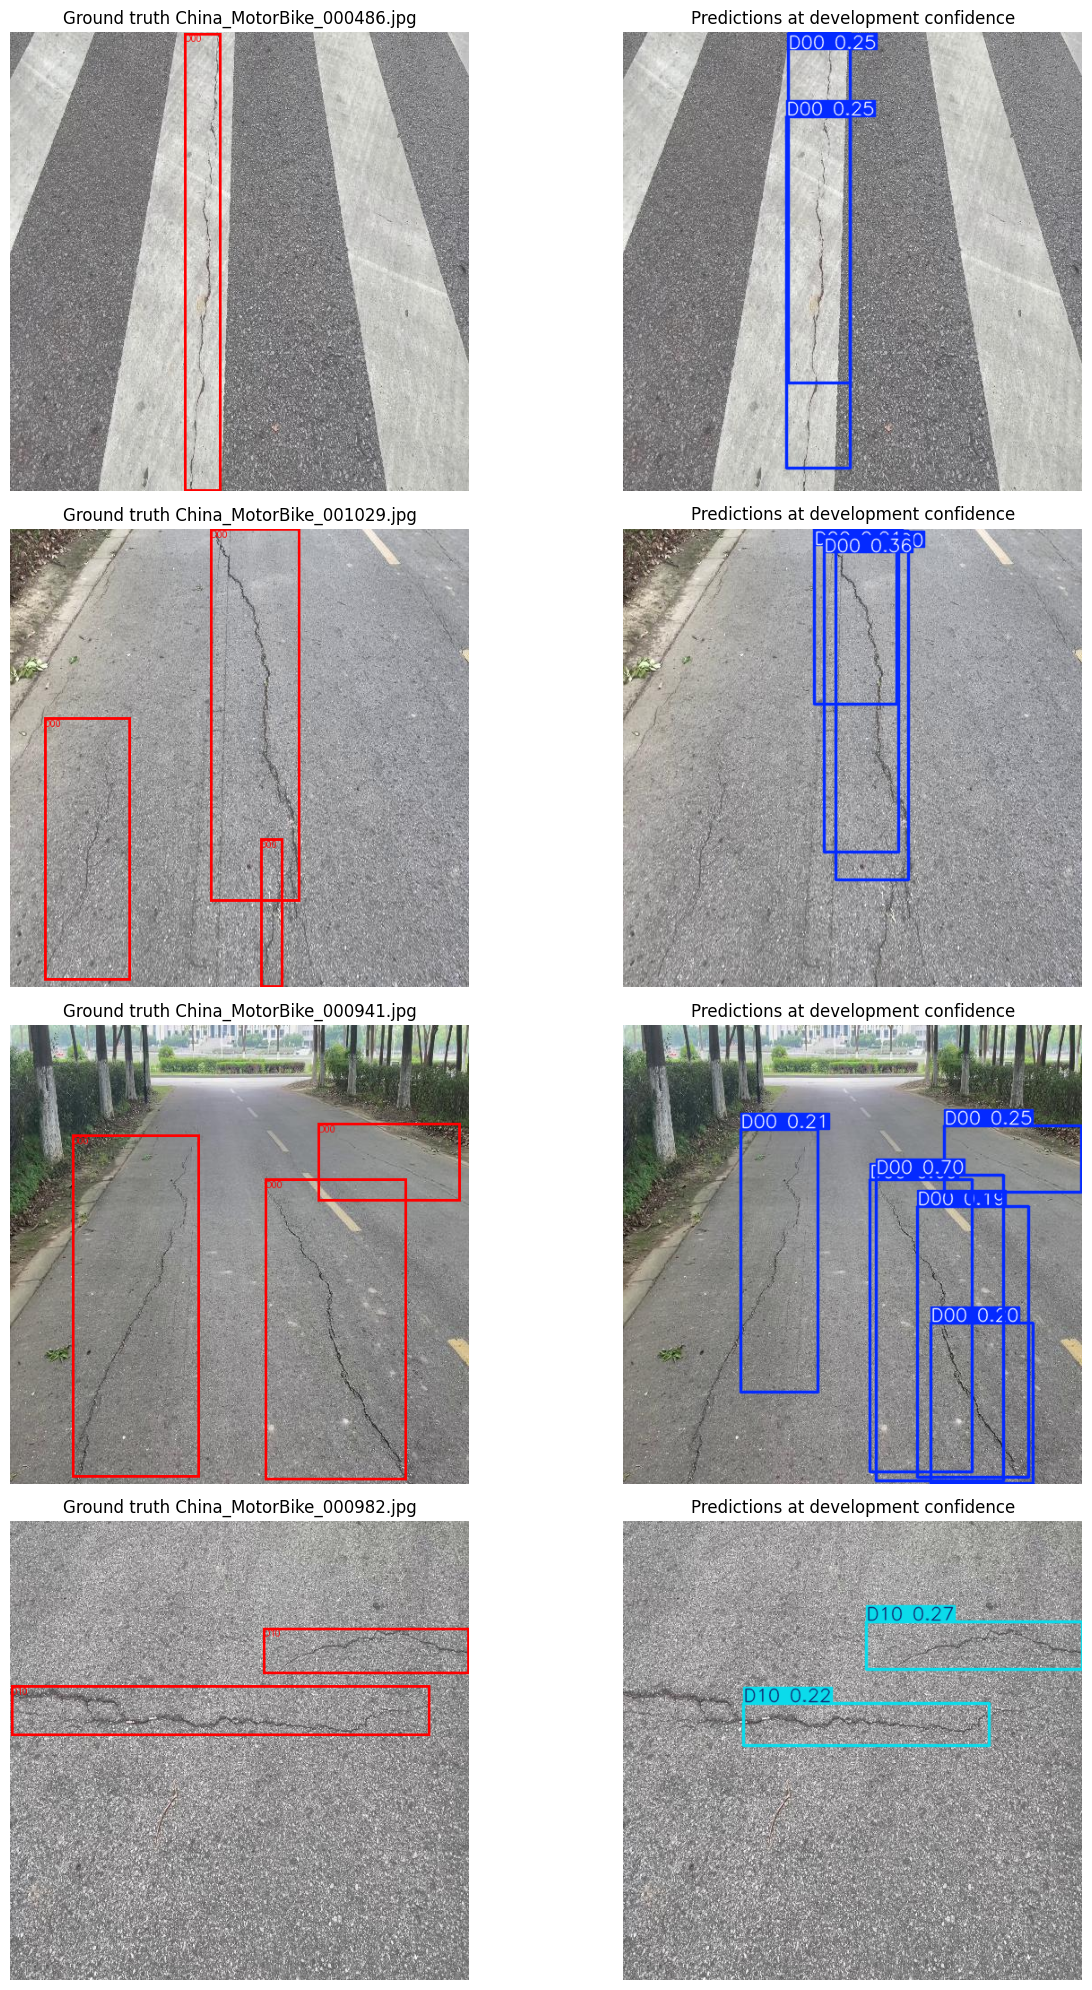

Results saved to /kaggle/working/roadscan_experiments/model_bundle/predictions/predict
Fresh-process prediction succeeded 1

FINAL PACKAGE: /kaggle/working/roadscan_results.zip


# RoadScan experiment report

## Selection
| name               | weights    | checkpoint                                                                   |    map50 |   map50_95 |   precision |   recall |   epochs_completed |   seconds |   mosaic |   hsv_s |   hsv_v |
|:-------------------|:-----------|:-----------------------------------------------------------------------------|---------:|-----------:|------------:|---------:|-------------------:|----------:|---------:|--------:|--------:|
| E2_nano_standard   | yolo11n.pt | /kaggle/working/roadscan_experiments/runs/E2_nano_standard/weights/best.pt   | 0.303942 |   0.134977 |    0.353734 | 0.355506 |                 36 |   2808.44 |        1 |     0.7 |     0.4 |
| E3_nano_mild_color | yolo11n.pt | /kaggle/working/roadscan_experiments/runs/E3_nano_mild_color/weights/best.pt | 0.293716 |   0.125812 |    0.374793 | 0.321734 |                 35 |   2770.83 |        1 |     0.3 |     0.2 |
| E2_small_standard  | yolo11s.pt | /kaggle/working/roadscan_experiments/runs/E2_small_standard/weights/best.pt  | 0.289239 |   0.121193 |    0.390011 | 0.326394 |                 26 |   2796.49 |        1 |     0.7 |     0.4 |
| E3_nano_no_mosaic  | yolo11n.pt | /kaggle/working/roadscan_experiments/runs/E3_nano_no_mosaic/weights/best.pt  | 0.24953  |   0.113885 |    0.378232 | 0.284023 |                 38 |   2776.21 |        0 |     0.7 |     0.4 |

## E1 image-level comparison
| split          | model          |   macro_F1 |   micro_F1 |
|:---------------|:---------------|-----------:|-----------:|
| in_domain_dev  | ResNet18       |   0.60353  |   0.608974 |
| in_domain_dev  | YOLO11         |   0.71686  |   0.736842 |
| in_domain_dev  | AlwaysPositive |   0.351654 |   0.359984 |
| china_dev      | ResNet18       |   0.619768 |   0.684853 |
| china_dev      | YOLO11         |   0.714617 |   0.820531 |
| china_dev      | AlwaysPositive |   0.481794 |   0.523938 |
| in_domain_test | ResNet18       |   0.607634 |   0.594956 |
| in_domain_test | YOLO11         |   0.699772 |   0.70581  |
| in_domain_test | AlwaysPositive |   0.31884  |   0.323041 |
| us_external    | ResNet18       |   0.482594 |   0.715551 |
| us_external    | YOLO11         |   0.679426 |   0.845041 |
| us_external    | AlwaysPositive |   0.466511 |   0.539736 |

## E4 detection evaluation
| split          |   images |    mAP50 |   mAP50_95 |   precision |   recall |
|:---------------|---------:|---------:|-----------:|------------:|---------:|
| in_domain_dev  |     1000 | 0.446232 |  0.209101  |    0.532384 | 0.425547 |
| china_dev      |     1977 | 0.195438 |  0.0803409 |    0.261645 | 0.27232  |
| in_domain_test |      998 | 0.404648 |  0.178182  |    0.468394 | 0.422697 |
| us_external    |     4805 | 0.407619 |  0.209936  |    0.460767 | 0.441844 |

## E2 CPU latency
| trial             |   median_ms |   p95_ms |   threads |   images |
|:------------------|------------:|---------:|----------:|---------:|
| E2_nano_standard  |     71.0466 |  76.3957 |         2 |       20 |
| E2_small_standard |    149.049  | 163.62   |         2 |       20 |

## Interpretation and limitations
The highest mixed-development mAP50-95 selected the checkpoint, not any test result. Read actual epochs alongside the 45-minute cap. Per-class results and error categories are saved separately. No claim of zero overfitting, universal performance, or local Saudi success is supported. Filename blocks are sequence proxies, not trip IDs. pHash screens can miss near-duplicates or remove distinct similar roads.
Local test: PENDING. E5 retrieval, priority sensitivity and integrated application are outside this detector notebook. US has historical reference-model exposure; reserve a new independent local test for stronger evidence.
Image-level E1 compares pipelines at different input resolutions and cannot isolate architecture alone. Confidence maximizes development F1 and needs operational cost validation.
## Reuse
Run: python model_bundle/predict.py --image /path/to/road.jpg
Model weights and configuration were reloaded and tested in a fresh Python process.
## Required next evidence
40-80 safely captured local test images with YOLO labels; keep locations/trips disjoint and blur faces/plates. Never tune on this test set.

'/kaggle/working/roadscan_results.zip'

In [4]:
# E2 CPU comparison: identical inputs, image size, threads, warm-ups and timing scope.
cpu_rows=[]
for r in records:
    if r['name'] not in ['E2_nano_standard','E2_small_standard']:continue
    bm=YOLO(r['checkpoint']);elapsed=[]
    for i,p in enumerate(dev.path.head(25)):
        t=time.perf_counter();bm.predict(p,imgsz=640,conf=CONF,device='cpu',half=False,verbose=False)
        if i==0:torch.set_num_threads(2)
        if i>=5:elapsed.append((time.perf_counter()-t)*1000)
    cpu_rows.append(dict(trial=r['name'],median_ms=float(np.median(elapsed)),p95_ms=float(np.percentile(elapsed,95)),threads=torch.get_num_threads(),images=len(elapsed)))
pd.DataFrame(cpu_rows).to_csv(BASE/'E2_cpu_comparison.csv',index=False);display(pd.DataFrame(cpu_rows))
# Diagnostic train-vs-validation probe. Never used to select another model after tests.
probe=train.sample(n=min(1000,len(train)),random_state=42)
(BASE/'train_probe.txt').write_text(chr(10).join(probe.path))
probe_cfg=yaml.safe_load(Path(DATA).read_text());probe_cfg['val']=str(BASE/'train_probe.txt')
(BASE/'train_probe.yaml').write_text(yaml.safe_dump(probe_cfg))
pm=detector.val(data=str(BASE/'train_probe.yaml'),imgsz=640,device=0,batch=8,workers=2,plots=False,project=str(BASE/'evaluation'),name='training_diagnostic')
(BASE/'training_diagnostic.json').write_text(json.dumps(dict(images=len(probe),map50=float(pm.box.map50),map50_95=float(pm.box.map),warning='Training-set diagnostic is not independent accuracy. Gaps can reflect both overfitting and domain shift.'),indent=2))
# One-to-one IoU matching for explicit error categories on fixed development examples.
from torchvision.ops import box_iou
error_rows=[]
examples=dev.sample(n=min(100,len(dev)),random_state=42)
fig,axes=plt.subplots(4,2,figsize=(14,20))
for idx,r in enumerate(examples.itertuples()):
    im=Image.open(r.path).convert('RGB');w,h=im.size;gt=[];gcids=[]
    for line in Path(r.label).read_text().splitlines():
        if not line.strip():continue
        c,x,y,bw,bh=map(float,line.split());gcids.append(int(c));gt.append([(x-bw/2)*w,(y-bh/2)*h,(x+bw/2)*w,(y+bh/2)*h])
    pred=detector.predict(r.path,imgsz=640,conf=CONF,device=0,verbose=False)[0]
    pb=pred.boxes.xyxy.cpu();pc=pred.boxes.cls.cpu().numpy().astype(int)
    ious=box_iou(torch.tensor(gt,dtype=torch.float32).reshape(-1,4),pb).numpy()
    pairs=sorted([(float(ious[g,p]),g,p) for g in range(len(gt)) for p in range(len(pc)) if gcids[g]==pc[p] and ious[g,p]>=.5],reverse=True)
    usedg=set();usedp=set()
    for _,g,p in pairs:
        if g not in usedg and p not in usedp:usedg.add(g);usedp.add(p)
    for g,c in enumerate(gcids):
        if g in usedg:continue
        overlap=ious[g].max() if len(pc) else 0.
        kind='wrong_class' if any(ious[g,p]>=.5 and pc[p]!=c for p in range(len(pc))) else ('localization' if overlap>=.1 else 'missed_damage')
        error_rows.append(dict(image=Path(r.path).name,class_name=CLASSES[c],error=kind,best_iou=float(overlap)))
    for p,c in enumerate(pc):
        if p not in usedp:error_rows.append(dict(image=Path(r.path).name,class_name=CLASSES[c],error='false_positive_or_duplicate',best_iou=float(ious[:,p].max()) if len(gt) else 0.))
    if idx<4:
        draw=ImageDraw.Draw(im)
        for box,c in zip(gt,gcids):draw.rectangle(box,outline='red',width=3);draw.text((box[0],box[1]),CLASSES[c],fill='red')
        axes[idx,0].imshow(im);axes[idx,0].set_title('Ground truth '+Path(r.path).name);axes[idx,0].axis('off')
        axes[idx,1].imshow(pred.plot()[...,::-1]);axes[idx,1].set_title('Predictions at development confidence');axes[idx,1].axis('off')
errors=pd.DataFrame(error_rows,columns=['image','class_name','error','best_iou']);errors.to_csv(BASE/'error_examples.csv',index=False)
if len(errors):display(errors.groupby(['class_name','error']).size().unstack(fill_value=0))
fig.tight_layout();fig.savefig(BASE/'ground_truth_vs_predictions.jpg',dpi=140);plt.show()
# Portable model package and a genuinely fresh Python-process reload test.
bundle=BASE/'model_bundle';bundle.mkdir(exist_ok=True)
shutil.copy2(WINNER,bundle/'best.pt')
config=dict(classes=CLASSES,imgsz=640,confidence=CONF,source_weights=WINNER,ultralytics=ultralytics.__version__,local_validation='PENDING - no local Saudi test attached',intended_use='Research prototype; human review required')
(bundle/'config.json').write_text(json.dumps(config,indent=2))
infer_lines=[
 'from pathlib import Path', 'import argparse, json', 'from ultralytics import YOLO',
 'p=argparse.ArgumentParser();p.add_argument("--image",required=True);args=p.parse_args()',
 'root=Path(__file__).resolve().parent', 'cfg=json.loads((root/"config.json").read_text())',
 'model=YOLO(str(root/"best.pt"))',
 'results=model.predict(args.image,imgsz=cfg["imgsz"],conf=cfg["confidence"],device="cpu",save=True,project=str(root/"predictions"),verbose=False)',
 'print("Fresh-process prediction succeeded",len(results))'
]
(bundle/'predict.py').write_text(chr(10).join(infer_lines))
(bundle/'requirements.txt').write_text('ultralytics=='+ultralytics.__version__+chr(10))
reload=subprocess.run([sys.executable,str(bundle/'predict.py'),'--image',dev.path.iloc[0]],capture_output=True,text=True,timeout=180)
(BASE/'fresh_process_reload.txt').write_text(reload.stdout+reload.stderr)
assert reload.returncode==0, 'Fresh-process reload failed; inspect reload log.'
print(reload.stdout)
report=['# RoadScan experiment report', '', '## Selection', experiments.to_markdown(index=False), '', '## E1 image-level comparison',pd.DataFrame(image_rows).to_markdown(index=False),'','## E4 detection evaluation',pd.DataFrame(det_rows).to_markdown(index=False),'','## E2 CPU latency',pd.DataFrame(cpu_rows).to_markdown(index=False),'','## Interpretation and limitations','The highest mixed-development mAP50-95 selected the checkpoint, not any test result. Read actual epochs alongside the 45-minute cap. Per-class results and error categories are saved separately. No claim of zero overfitting, universal performance, or local Saudi success is supported. Filename blocks are sequence proxies, not trip IDs. pHash screens can miss near-duplicates or remove distinct similar roads.','Local test: PENDING. E5 retrieval, priority sensitivity and integrated application are outside this detector notebook. US has historical reference-model exposure; reserve a new independent local test for stronger evidence.','Image-level E1 compares pipelines at different input resolutions and cannot isolate architecture alone. Confidence maximizes development F1 and needs operational cost validation.','## Reuse','Run: python model_bundle/predict.py --image /path/to/road.jpg','Model weights and configuration were reloaded and tested in a fresh Python process.','## Required next evidence','40-80 safely captured local test images with YOLO labels; keep locations/trips disjoint and blur faces/plates. Never tune on this test set.']
(BASE/'REPORT.md').write_text(chr(10).join(report))
(bundle/'MODEL_CARD.md').write_text(chr(10).join(report[-12:]))
checks={str(p.relative_to(BASE)):hashlib.sha256(p.read_bytes()).hexdigest() for p in BASE.rglob('*') if p.is_file() and p.name!='SHA256.json'}
(BASE/'SHA256.json').write_text(json.dumps(checks,indent=2))
archive=package_snapshot();print('FINAL PACKAGE:',archive)
display(Markdown((BASE/'REPORT.md').read_text()))

with (BASE/'REPORT.md').open('a') as fh:fh.write(chr(10)+'Recovery: all training came from version 358996529. Evaluation was resumed with explicit lists of at most 8 images after CUDA OOM. No models were retrained or selected on test results.')
package_snapshot()
